# Повітряні тривоги України: базовий аналіз

Виконаний огляд відтворюваного Python-проєкту. Основне джерело — волонтерський CSV. О 00:00 Europe/Kyiv прогнозуємо добу, що саме починається. О 00:00 1 жовтня дані готові тільки до 29 вересня: 30 вересня — проміжний крок, 1 жовтня — ціль. Це «післязавтра» відносно останньої готової доби. Дві цілі: записані початки та години за об’єднаними інтервалами. Авторські `naive=True` 30 хвилин збережено. Базова версія без Telegram незмінна; наприкінці додано окремий умовний текстовий експеримент.

Повний експеримент: `python run.py run --workers 4`. Цей notebook читає його артефакти, повторює незалежний аудит і демонструє прогноз із доступного минулого.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'config.json').exists():
    raise RuntimeError('Запустіть notebook з кореня air_raid_analysis')
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
import numpy as np
from IPython.display import display, Image
from airraid.sources import load_ledger, as_of, snapshot_at, verify_checksums
from airraid.series import midnight, day_hours
from airraid.evaluation import make_tasks
from airraid.models import forecast_task
DATA, REPORTS = ROOT / 'data', ROOT / 'reports'
protocol = json.loads((REPORTS / 'protocol.json').read_text())
snapshots = json.loads((DATA / 'snapshots.json').read_text())
ledger = load_ledger(DATA / 'event_ledger.csv.gz')
print('Перевірено файлів:', verify_checksums(DATA))
display(pd.Series(json.loads((DATA / 'provenance.json').read_text())))

Перевірено файлів: 6


repository             https://github.com/Vadimkin/ukrainian-air-raid...
snapshot_count                                                       100
latest                          bf0c323c78e3e4508721458797dcd38c95df13f3
latest_available_at                                 2026-10-11T04:50:19Z
latest_rows                                                       115989
ledger_versions                                                   115989
earliest_replay_at                                  2026-07-04T03:28:41Z
publication_policy     successful GitHub Actions run completion after...
note                   Base rows are conservatively available only at...
dtype: object

## Перевірка джерела

Дублікати — повний збіг region/started_at/finished_at/naive. Однакова тривалість не є дублікатом. Шість нульових і 14 довгих інтервалів не вилучаються автоматично. Не кожна відсутність запису доводить відсутність реальної тривоги: допуск регіону використовує індикатор недавньої активності, а не незалежний журнал повноти.

In [2]:
audit = json.loads((REPORTS / 'source_audit.json').read_text())
display(pd.Series({k:v for k,v in audit.items() if not isinstance(v, (list, dict))}))
display(pd.read_csv(REPORTS / 'coverage.csv')[['region','eligible','recent_event_days','last_recorded_start']])
duration_minutes = (ledger.finished_at-ledger.started_at).dt.total_seconds()/60
assert (duration_minutes[ledger.naive] == 30).all()
print('Авторські 30 хвилин збережено; дублікати:', audit['duplicate_rows'])

rows                                                                           115989
duplicate_rows                                                                      0
missing_timestamps                                                                  0
negative_durations                                                                  0
zero_durations                                                                      6
over_24_hours                                                                      14
max_duration_hours                                                            178.265
naive_rows                                                                       5812
naive_30_minutes_preserved                                                       True
finished_before_publication                                                      True
source_message_ids_nondecreasing                                                 True
snapshots                                             

,region,eligible,recent_event_days,last_recorded_start
0,Івано-Франківська область,True,2,2026-09-01T18:37:00+00:00
1,Волинська область,True,28,2026-09-11T09:34:18+00:00
2,Вінницька область,True,18,2026-09-12T02:21:00+00:00
3,Дніпропетровська область,True,30,2026-09-12T03:00:46+00:00
4,Донецька область,True,29,2026-09-11T16:25:10+00:00
5,Житомирська область,True,22,2026-09-12T02:28:10+00:00
6,Закарпатська область,False,0,2026-07-30T01:26:50+00:00
7,Запорізька область,True,30,2026-09-12T00:21:34+00:00
8,Київ,True,25,2026-09-11T20:53:24+00:00
9,Київська область,True,29,2026-09-12T02:34:40+00:00


Авторські 30 хвилин збережено; дублікати: 0


## Київська доба та доступність

Показуємо різницю між датою події й датою доступності CSV. Години прогнозуються через частку доби, що автоматично враховує 23/25 годин. Незавершена active-подія не отримує вигаданого finish; відповідна мітка неготова.

In [3]:
display(pd.DataFrame({'date':['2026-03-29','2026-10-25','2026-10-12'],
                      'day_hours':[day_hours(d) for d in ['2026-03-29','2026-10-25','2026-10-12']]}))
origin = midnight(protocol['test_start'])
snapshot = snapshot_at(snapshots, origin)
known = as_of(ledger, origin)
assert (known.available_at <= origin).all()
display(pd.Series({'origin':origin.isoformat(),'snapshot':snapshot['sha'],
                  'snapshot_available_at':snapshot['available_at'],'known_rows':len(known)}))

,date,day_hours
0,2026-03-29,23.0
1,2026-10-25,25.0
2,2026-10-12,24.0


origin                                  2026-09-13T00:00:00+03:00
snapshot                 5c0b2e82dc39171c496726864897a0ae0b012000
snapshot_available_at                        2026-09-12T03:48:54Z
known_rows                                                 111529
dtype: object

## Тренд до фінального тесту

Добові ряди та середні за сім минулих днів. Ряди описують зареєстровані інтервали. Не оцінюємо причинність або грошові втрати.

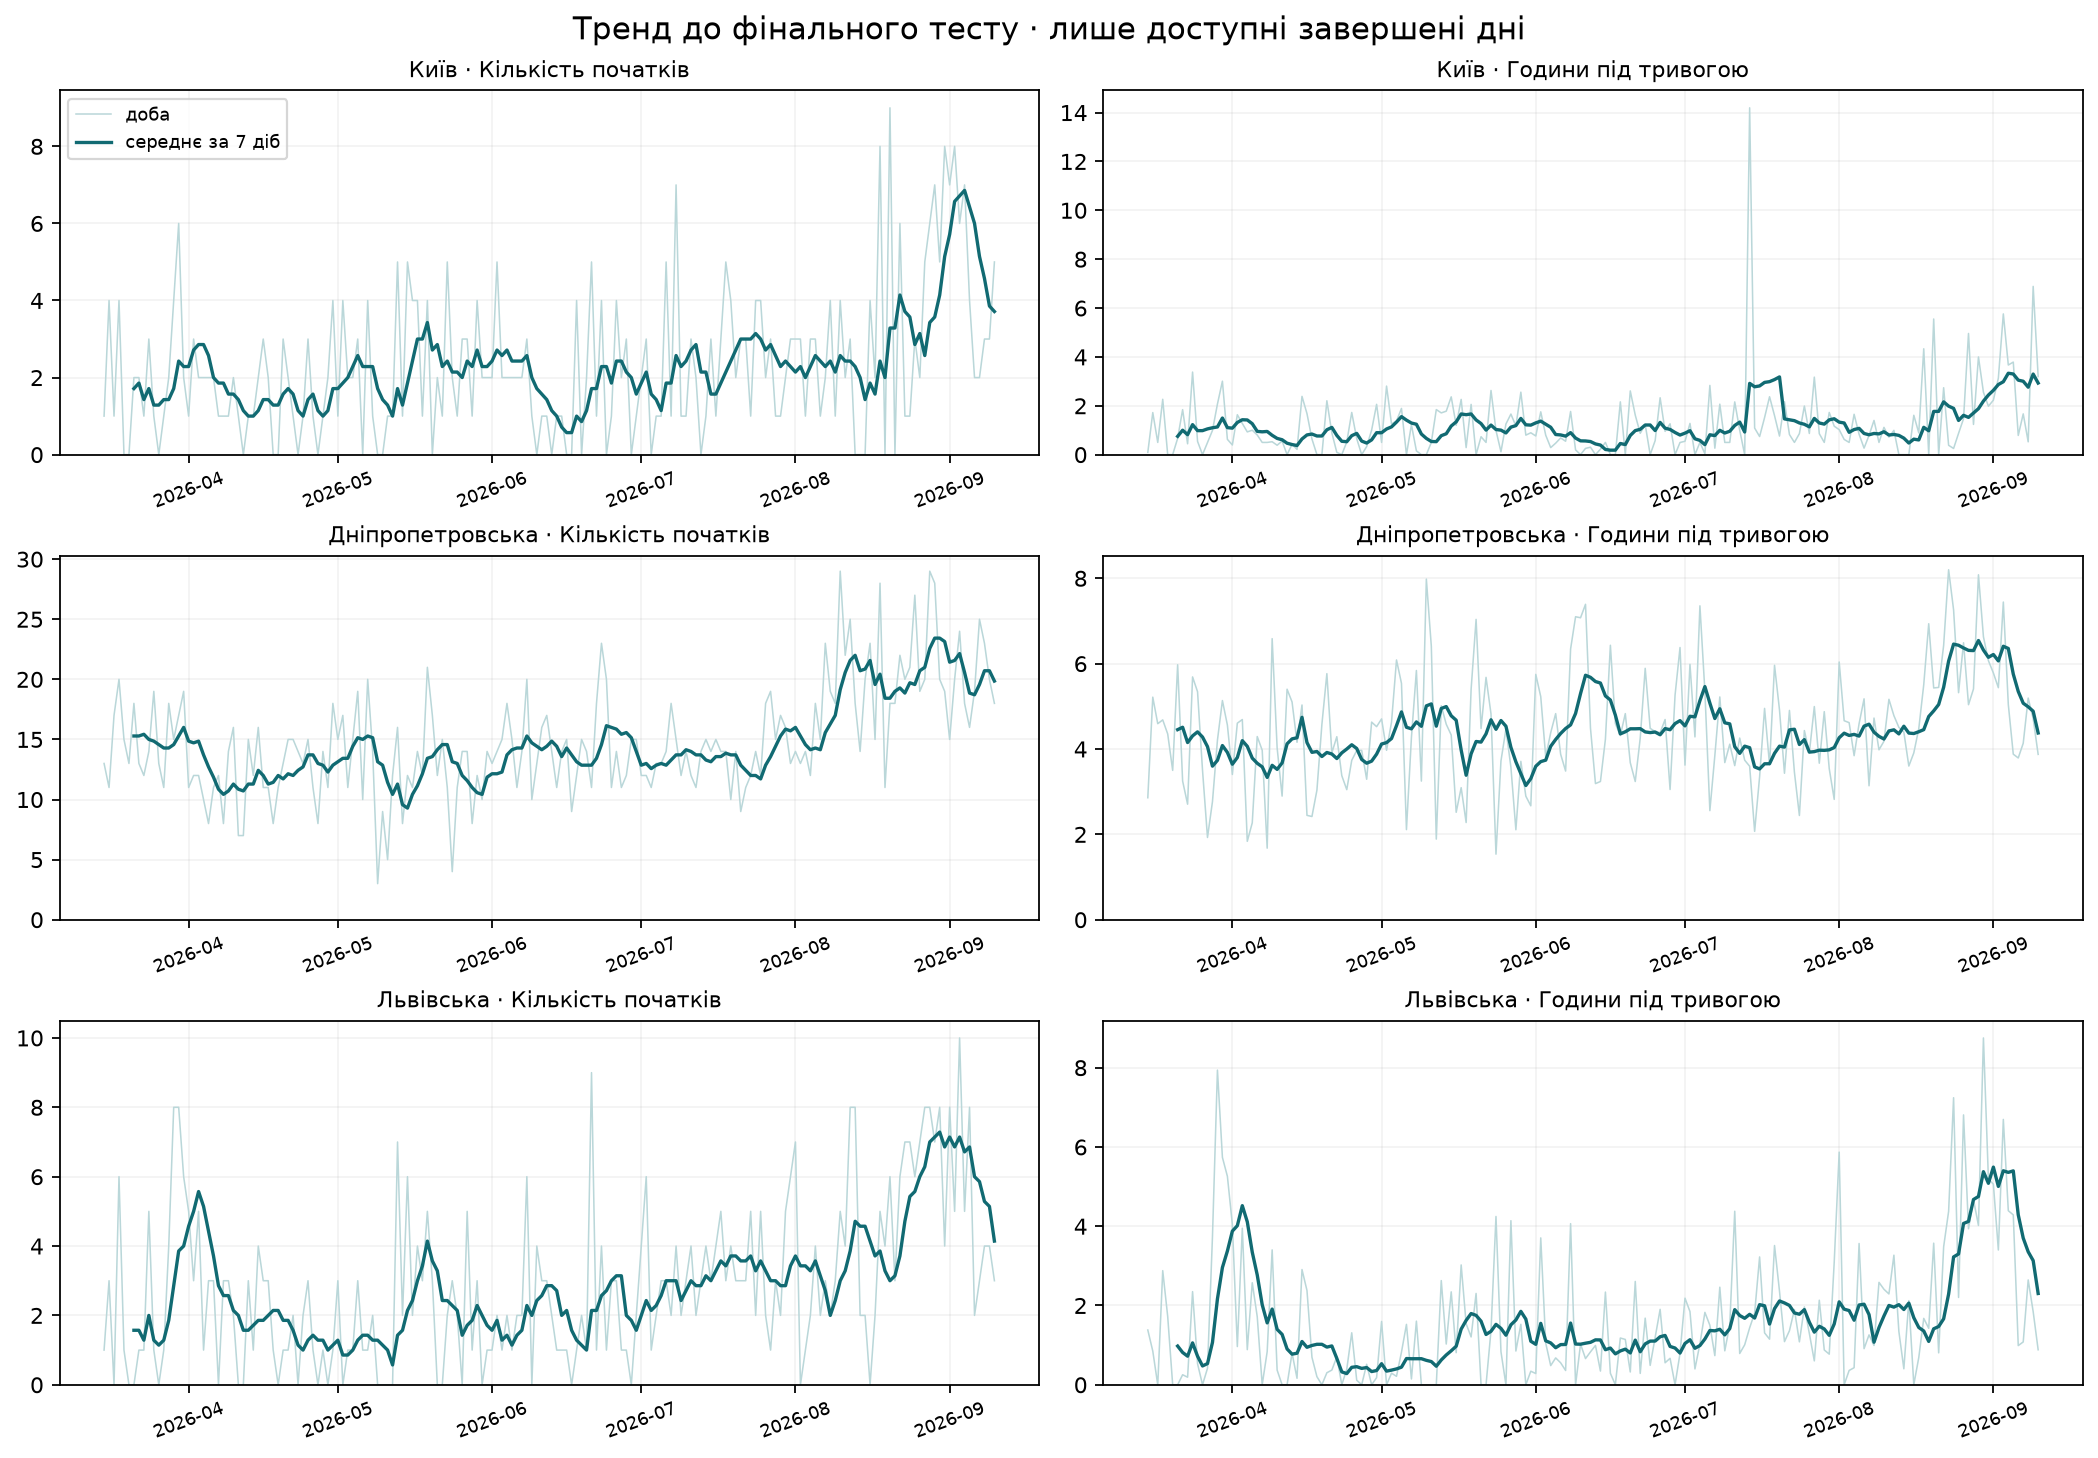

,region,target,recent_n,previous_n,recent_mean,previous_mean,difference
0,Івано-Франківська область,count,27,30,0.074074,0.066667,0.007407
1,Івано-Франківська область,hours,27,30,0.024383,0.033074,-0.008691
2,Волинська область,count,30,30,3.600000,3.833333,-0.233333
3,Волинська область,hours,30,30,3.799148,4.210769,-0.411620
4,Вінницька область,count,30,30,1.900000,0.866667,1.033333
5,Вінницька область,hours,30,30,0.878769,0.354778,0.523991
6,Дніпропетровська область,count,30,30,20.433333,15.433333,5.000000
7,Дніпропетровська область,hours,30,30,5.439769,4.159852,1.279917
8,Донецька область,count,30,30,4.600000,3.533333,1.066667
9,Донецька область,hours,30,30,3.136926,3.136648,0.000278


In [4]:
display(Image(filename=str(REPORTS/'figures/history.png')))
display(pd.read_csv(REPORTS/'trend_comparison.csv').head(12))

## Сезонність до моделювання

Одна зведена фігура з двома шкалами для кількості й годин. Період перед першою валідацією; нульові дні включені за припущенням про покриття. Таблиця містить n, середнє, медіану та відхилення від середнього регіону.

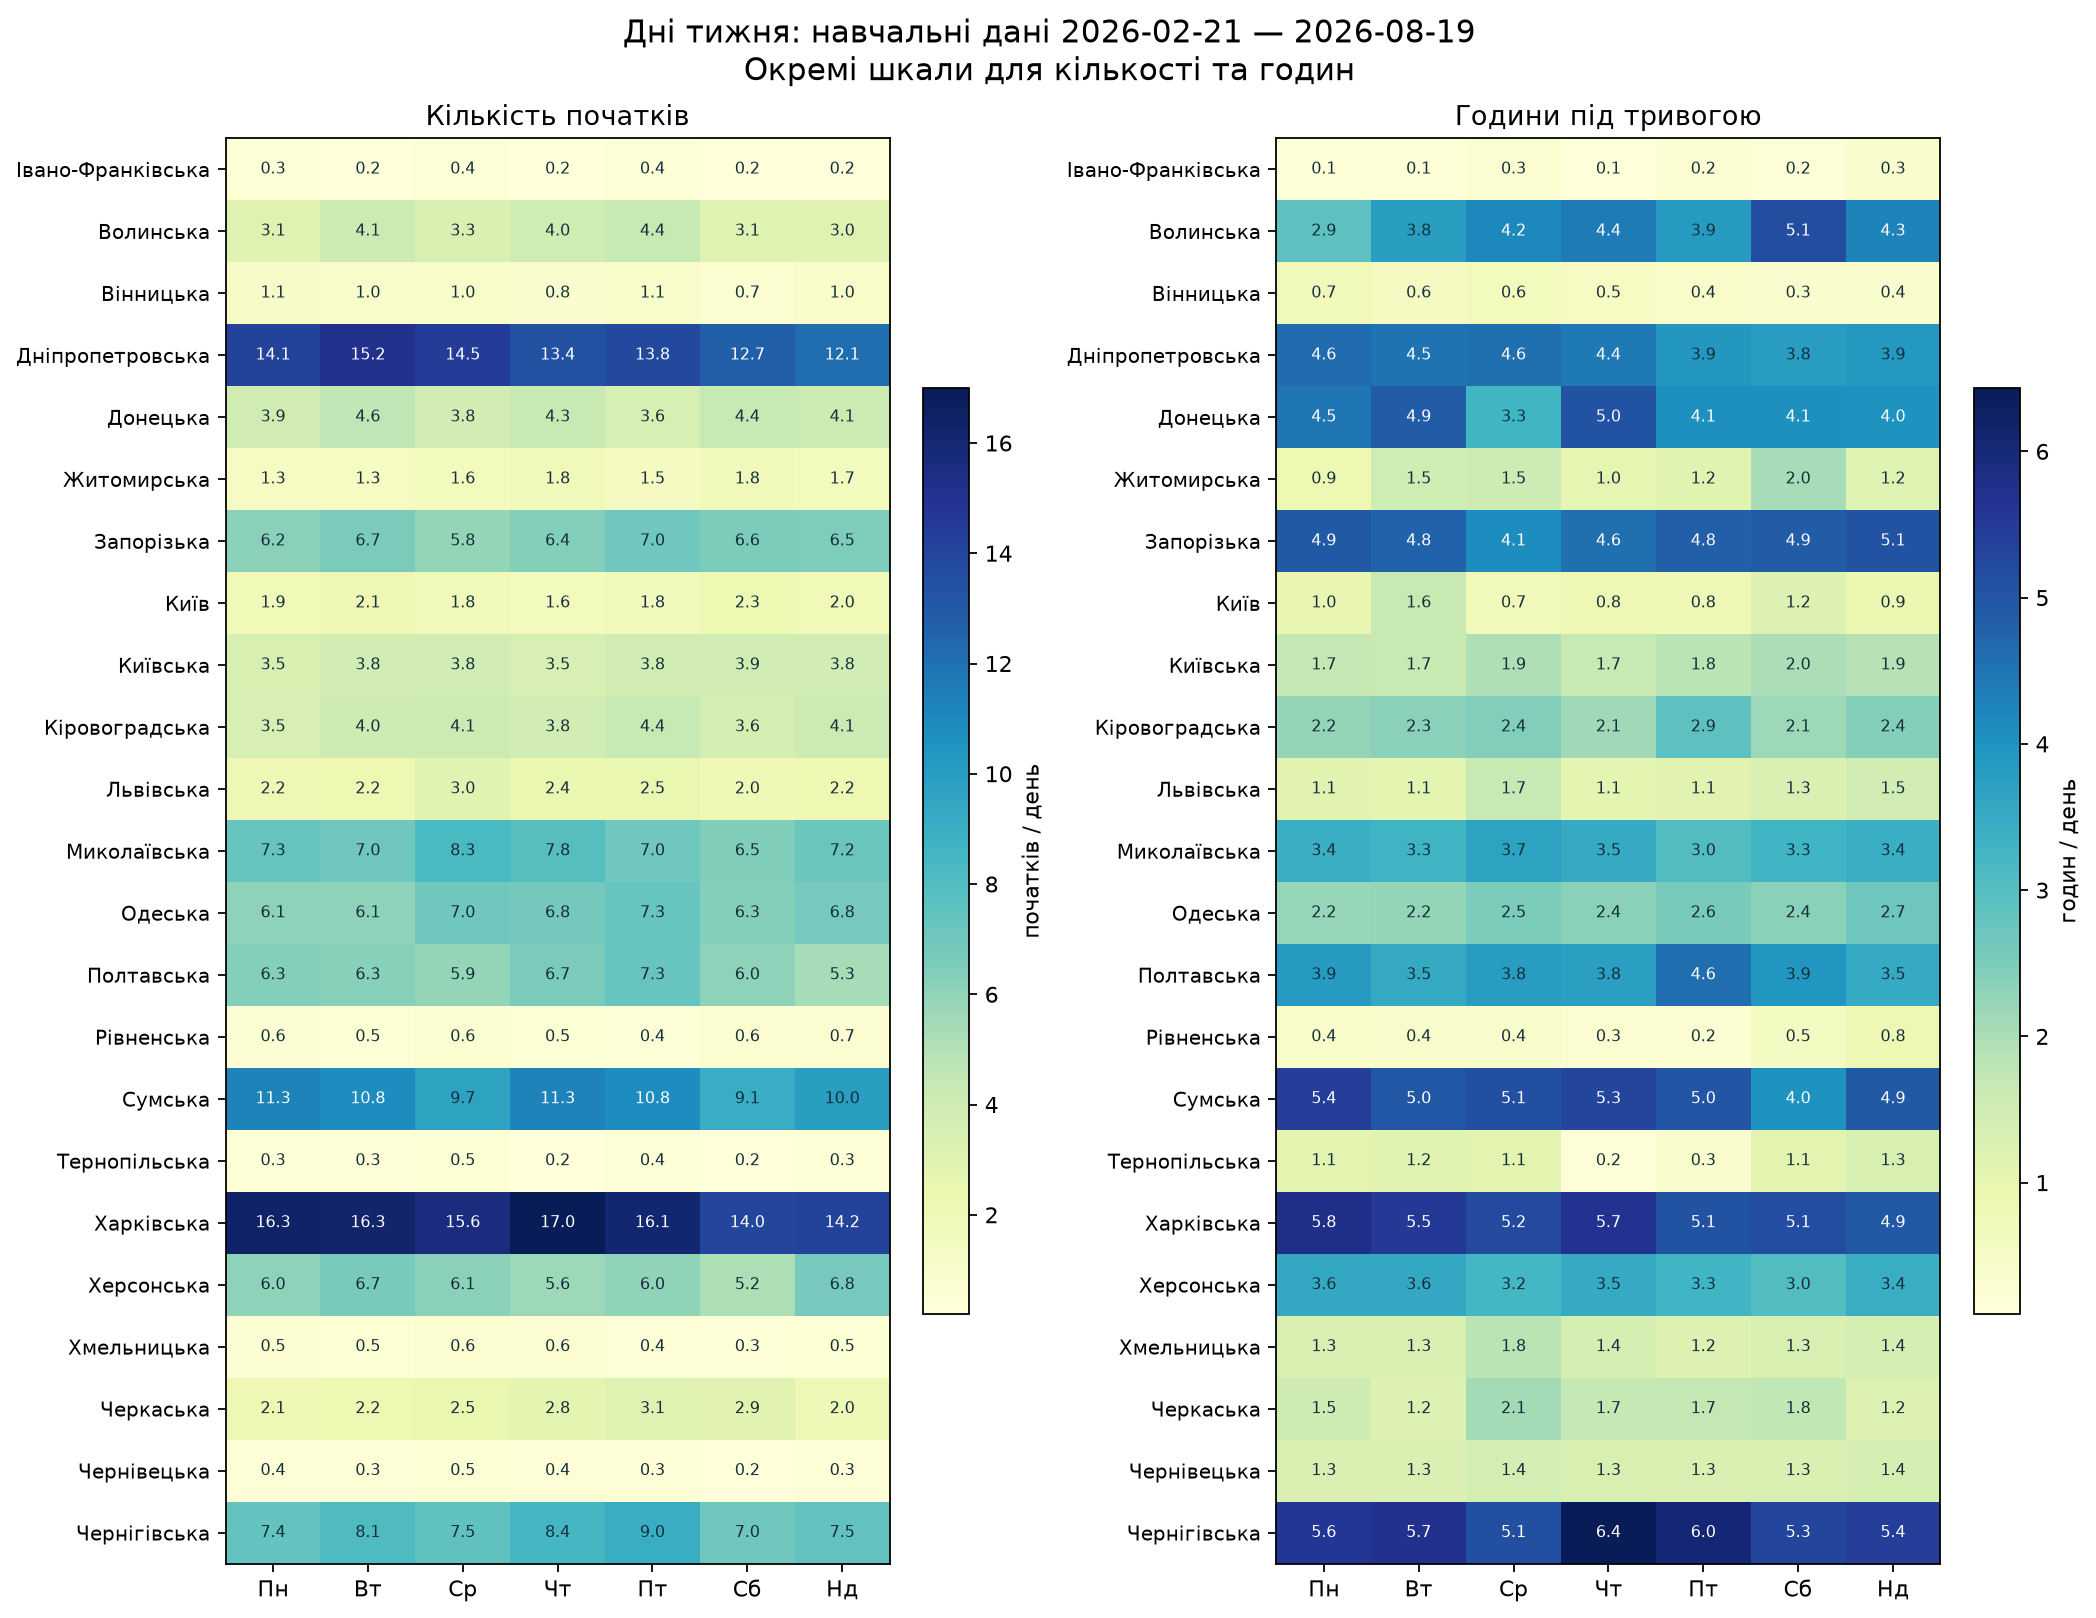

,region,target,weekday,n,mean,median,region_mean,difference_from_region_mean,weekday_name
98,Київ,count,0,26,1.923077,1.500000,1.916667,0.006410,Пн
99,Київ,count,1,26,2.115385,1.500000,1.916667,0.198718,Вт
100,Київ,count,2,26,1.769231,1.000000,1.916667,-0.147436,Ср
101,Київ,count,3,25,1.600000,1.000000,1.916667,-0.316667,Чт
102,Київ,count,4,25,1.760000,2.000000,1.916667,-0.156667,Пт
103,Київ,count,5,26,2.269231,2.000000,1.916667,0.352564,Сб
104,Київ,count,6,26,1.961538,2.000000,1.916667,0.044872,Нд
105,Київ,hours,0,26,0.979615,0.724444,1.016505,-0.036889,Пн
106,Київ,hours,1,26,1.648002,0.874722,1.016505,0.631498,Вт
107,Київ,hours,2,26,0.738739,0.522083,1.016505,-0.277765,Ср


analysis_origin                            2026-08-21T00:00:00+03:00
source_available_at                             2026-08-20T01:23:46Z
snapshot_sha                7f7a546078524cc7feb937a6e80bdf283e74e15d
start                                                     2026-02-21
end                                                       2026-08-19
only_pre_validation_data                                        True
training_rows                                                   4140
censored_rows                                                      0
weekday_mapping_checked                                         True
table_mean_reconciled                                           True
stl_used                                                       False
dtype: object

In [5]:
display(Image(filename=str(REPORTS/'figures/weekday_profiles.png')))
weekday = pd.read_csv(REPORTS/'weekday_differences.csv')
display(weekday.query("region == 'Київ'"))
display(pd.Series(json.loads((REPORTS/'seasonality_audit.json').read_text())))

## ACF і користь сезонного варіанта

Лінійний тренд вилучено. Лаги 7/14/21 є дослідницькими; поточкові межі 95% не враховують багато порівнянь. Пік не є доказом тижневої закономірності. Остаточний варіант вибрано за попередньою валідацією. STL не використовується.

lag                                  7      14     21
region                    target                     
Івано-Франківська область count  -0.082  0.059 -0.112
                          hours  -0.067 -0.017 -0.130
Волинська область         count   0.129  0.080 -0.140
                          hours  -0.043  0.048 -0.081
Вінницька область         count  -0.162  0.001 -0.098
                          hours  -0.131 -0.022  0.036
Дніпропетровська область  count   0.075  0.063 -0.066
                          hours   0.105 -0.102  0.062
Донецька область          count   0.001 -0.088  0.051
                          hours   0.031  0.127 -0.080
Житомирська область       count   0.088  0.040  0.018
                          hours  -0.082 -0.110 -0.096
Запорізька область        count   0.082 -0.110 -0.096
                          hours   0.046  0.036 -0.054
Київ                      count  -0.110  0.031 -0.100
                          hours  -0.045 -0.045  0.005
Київська область          count  -0.066  0.040 -0.111
                          hours   0.104  0.059 -0.162
Кіровоградська область    count  -0.067 -0.046 -0.074
                          hours   0.097  0.041 -0.121
Львівська область         count  -0.031  0.032 -0.046
                          hours   0.011 -0.071 -0.058
Миколаївська область      count  -0.033 -0.000  0.044
                          hours  -0.066 -0.004 -0.043
Одеська область           count   0.062  0.069  0.020
                          hours   0.118  0.059 -0.106
Полтавська область        count  -0.097  0.117 -0.018
                          hours  -0.053  0.010  0.070
Рівненська область        count  -0.027  0.114  0.034
                          hours   0.105 -0.010  0.004
Сумська область           count   0.113  0.001  0.045
                          hours   0.196  0.129  0.069
Тернопільська область     count  -0.090  0.071 -0.141
                          hours  -0.056 -0.074  0.002
Харківська область        count   0.040  0.042  0.039
                          hours   0.025  0.098  0.024
Херсонська область        count  -0.032 -0.025  0.039
                          hours   0.083 -0.004  0.016
Хмельницька область       count  -0.137  0.070 -0.140
                          hours  -0.071 -0.055 -0.000
Черкаська область         count  -0.186  0.047 -0.025
                          hours  -0.034 -0.026 -0.022
Чернівецька область       count  -0.091  0.038 -0.094
                          hours  -0.042 -0.108  0.015
Чернігівська область      count  -0.049  0.065  0.012
                          hours  -0.203  0.144 -0.043

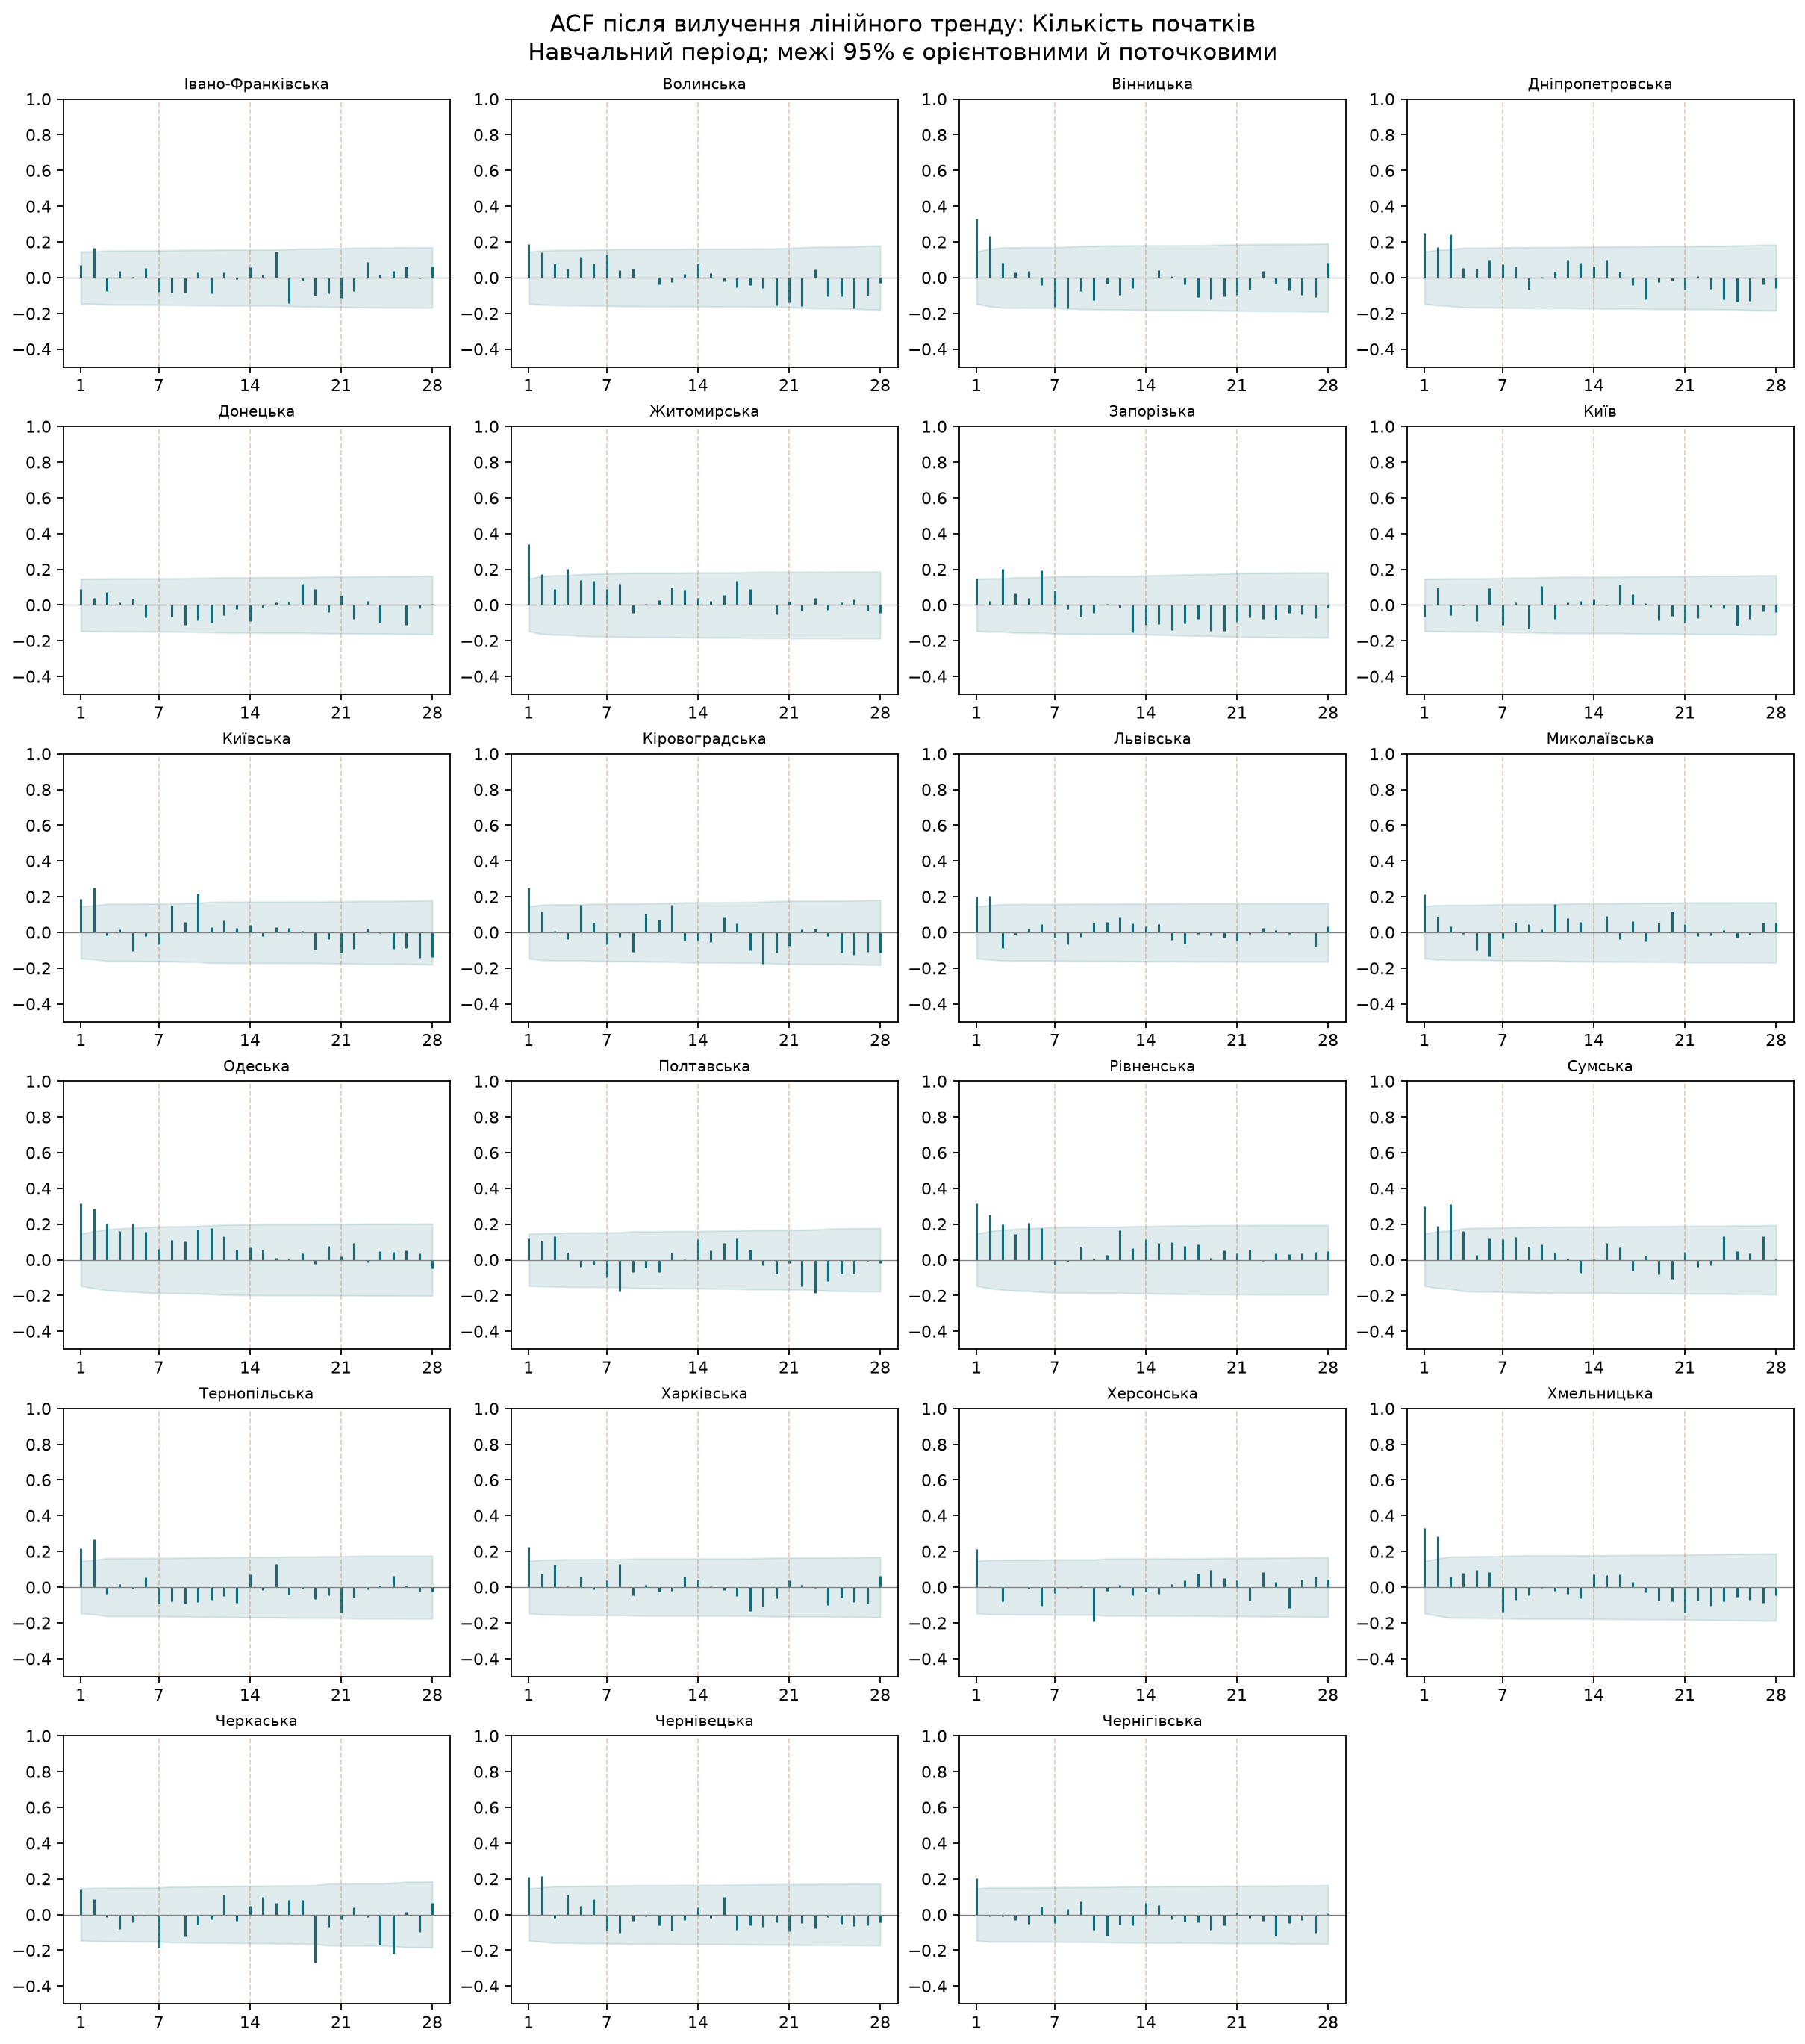

conclusion
переконливої користі сезонності не виявлено                            85
сезонність покращує прогноз, ACF не дає переконливого підтвердження     7
Name: порівнянь, dtype: int64

,region,target,family,nonseasonal_mae,seasonal_mae,nonseasonal_rmse,seasonal_rmse,mae_improvement,relative_mae_improvement,acf_7,acf_7_exploratory_positive,conclusion
28,Київ,count,ARIMA,2.701548,2.668384,3.067262,3.050860,0.033164,0.012276,-0.109521,False,переконливої користі сезонності не виявлено
29,Київ,count,Exponential smoothing,2.497402,2.537574,2.846349,2.890901,-0.040172,-0.016086,-0.109521,False,переконливої користі сезонності не виявлено
30,Київ,hours,ARIMA,1.660148,1.688947,2.100918,2.127313,-0.028799,-0.017347,-0.044932,False,переконливої користі сезонності не виявлено
31,Київ,hours,Exponential smoothing,1.686168,1.725030,2.124035,2.163680,-0.038862,-0.023048,-0.044932,False,переконливої користі сезонності не виявлено


In [6]:
acf = pd.read_csv(REPORTS/'acf.csv')
display(acf.query('lag in [7,14,21]').pivot(index=['region','target'],columns='lag',values='acf').round(3))
display(Image(filename=str(REPORTS/'figures/acf_count.png'),width=900))
comparison = pd.read_csv(REPORTS/'seasonal_comparison.csv')
display(comparison.groupby('conclusion').size().rename('порівнянь'))
display(comparison.query("region == 'Київ'"))

## Чесне оцінювання

Для кожного origin — власний snapshot та до 180 доступних днів. Доступність обмежує останній готовий день, тому горизонт може бути 2–6 кроків. Валідаційні мітки зафіксовано до тесту. Обмеження виходу застосовано до обчислення метрик; дробова кількість є очікуваним значенням. Macro MAE — середнє регіональних MAE, без загального показника годин.

,target,model,baseline_mae,selected_mae,baseline_rmse,selected_rmse,regions,forecast_days,relative_mae_improvement,meets_5_percent
0,count,last,2.545606,2.004518,3.198795,2.591188,23,643,0.212558,True
1,count,mean_7,2.020096,2.004518,2.583646,2.591188,23,643,0.007712,False
2,count,validation_selected_baseline,2.207319,2.004518,2.776475,2.591188,23,643,0.091877,True
3,count,weekly_naive,2.570566,2.004518,3.326104,2.591188,23,643,0.220204,True
4,hours,last,1.840236,1.453168,2.528251,2.007970,23,643,0.210336,True
5,hours,mean_7,1.497288,1.453168,2.028086,2.007970,23,643,0.029467,False
6,hours,validation_selected_baseline,1.467118,1.453168,2.067873,2.007970,23,643,0.009509,False
7,hours,weekly_naive,1.915194,1.453168,2.615334,2.007970,23,643,0.241242,True


,target,model,macro_mae,macro_rmse,regions,forecast_days
0,count,arima,2.073296,2.681066,23,643
1,count,ets_7,2.013448,2.572078,23,643
2,count,last,2.545606,3.198795,23,643
3,count,mean_7,2.020096,2.583646,23,643
4,count,sarima_7,2.074475,2.682329,23,643
5,count,ses,1.976707,2.546001,23,643
6,count,weekly_naive,2.570566,3.326104,23,643
7,hours,arima,1.456784,2.008170,23,643
8,hours,ets_7,1.457836,2.015840,23,643
9,hours,last,1.840236,2.528251,23,643


,target,model,baseline_mae,selected_mae,baseline_rmse,selected_rmse,regions,forecast_days,relative_mae_improvement,meets_5_percent
0,count,mean_7,2.020096,2.004518,2.583646,2.591188,23,643,0.007712,False
1,hours,mean_7,1.497288,1.453168,2.028086,2.007970,23,643,0.029467,False


Початковий критерій проти вибраного на валідації орієнтира, збережений для аудиту:


,target,model,macro_mae,macro_rmse,regions,forecast_days
0,count,baseline,2.207319,2.776475,23,643
1,count,selected,2.004518,2.591188,23,643
2,hours,baseline,1.467118,2.067873,23,643
3,hours,selected,1.453168,2.007970,23,643


,target,baseline_mae,selected_mae,relative_improvement,criterion_met
0,count,2.207319,2.004518,0.091877,True
1,hours,1.467118,1.453168,0.009509,False


,region,target,n,mae,rmse,model
0,Івано-Франківська область,count,27,0.370106,0.545839,ets_7
1,Івано-Франківська область,hours,27,0.157745,0.216027,ses
2,Волинська область,count,28,2.087573,2.586370,arima
3,Волинська область,hours,28,2.912478,4.019765,ets_7
4,Вінницька область,count,28,2.449917,3.038899,ets_7
5,Вінницька область,hours,28,1.115539,1.414644,ets_7
6,Дніпропетровська область,count,28,3.585850,4.746959,ets_7
7,Дніпропетровська область,hours,28,0.886713,1.131642,ses
8,Донецька область,count,28,1.314087,1.549729,ses
9,Донецька область,hours,28,1.941602,2.623550,ses


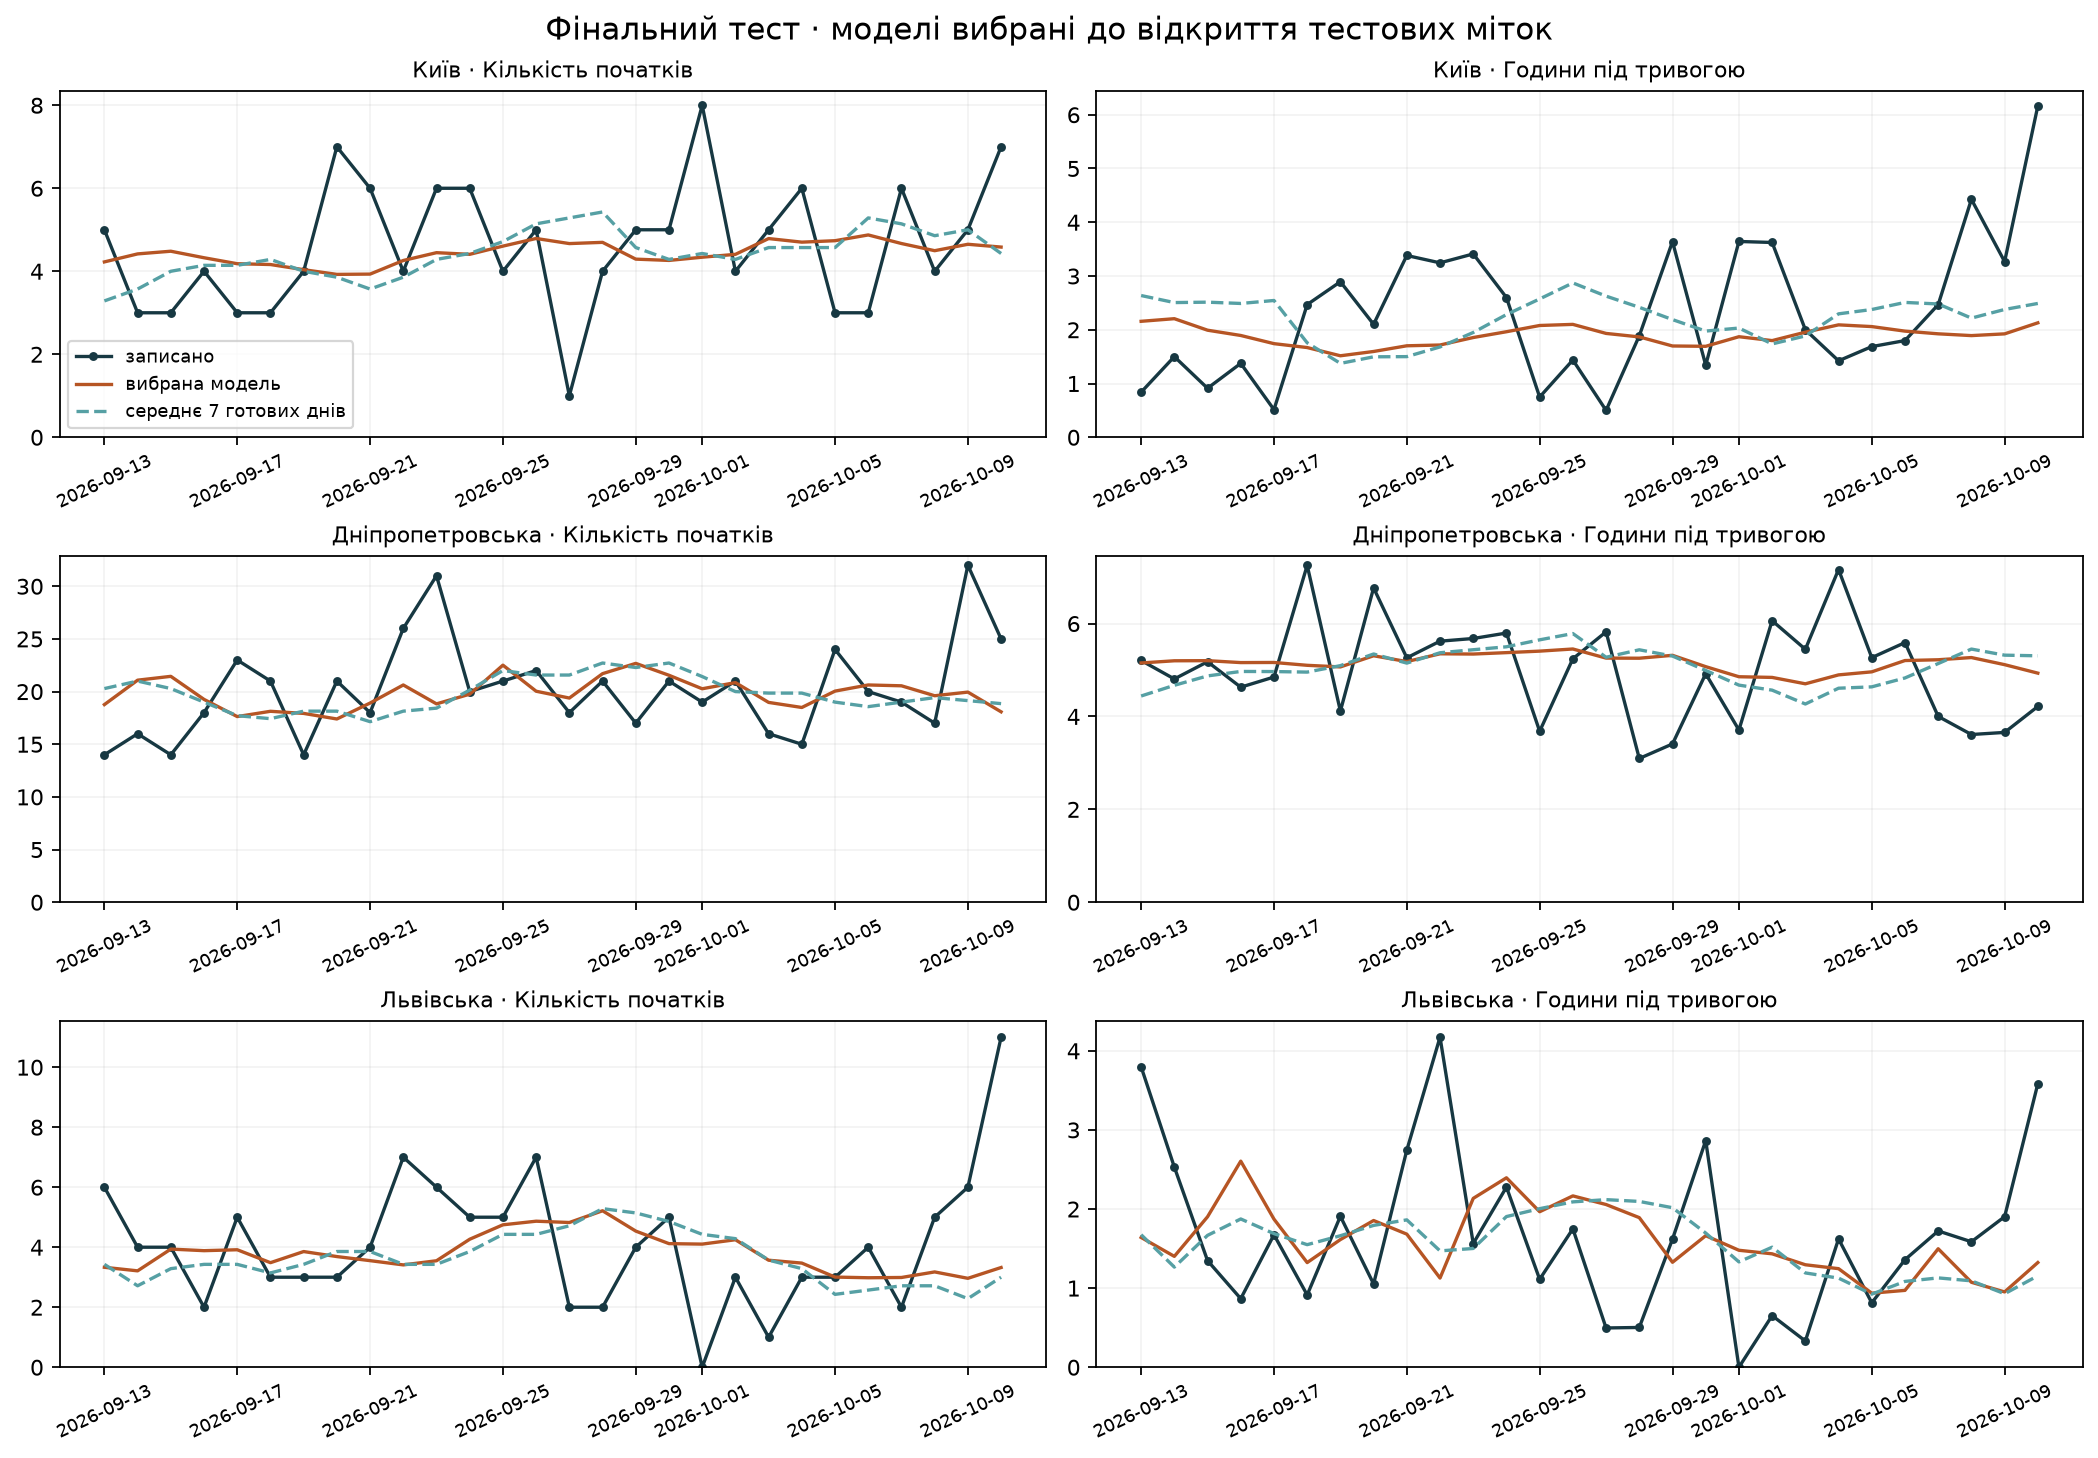

forecast_rows                                                      15722
all_finite                                                          True
nonnegative                                                         True
hours_bounded                                                       True
all_snapshots_before_origin                                         True
max_steps                                                              6
min_steps                                                              2
fallback_forecasts                                                    24
clipped_forecasts                                                     73
test_labels_excluded                                                   1
validation_labels_excluded                                             4
selection_label_snapshot        5c0b2e82dc39171c496726864897a0ae0b012000
selection_label_available_at                        2026-09-12T03:48:54Z
dtype: object

In [7]:
display(pd.read_csv(REPORTS/'baseline_comparison.csv'))
display(pd.read_csv(REPORTS/'test_macro_all_models.csv'))
display(pd.DataFrame(json.loads((REPORTS/'success_criteria_mean7.json').read_text())))
print('Початковий критерій проти вибраного на валідації орієнтира, збережений для аудиту:')
display(pd.read_csv(REPORTS/'test_macro_metrics.csv'))
display(pd.DataFrame(json.loads((REPORTS/'success_criteria.json').read_text())))
display(pd.read_csv(REPORTS/'results_by_region.csv'))
display(Image(filename=str(REPORTS/'figures/forecast_vs_actual.png')))
display(pd.Series(json.loads((REPORTS/'forecast_audit.json').read_text())))

## Приклад відтворення одного прогнозу

Для першого тестового дня в Києві повторюємо тільки вибрану на валідації модель. Входи беруться зі snapshot до origin. Перевіряємо збіг зі збереженим прогнозом. Далі додаємо штучний майбутній рядок: він не повинен змінити минулі входи.

In [8]:
selection = pd.read_csv(REPORTS/'model_selection.csv')
tasks, omissions = make_tasks(ledger,snapshots,protocol['config'],[protocol['test_start']],['Київ'])
task = tasks[0]
display(pd.Series({k:v for k,v in task.items() if k not in ['count','share']}))
predictions = pd.DataFrame(forecast_task(task))
chosen = selection.query("region == 'Київ' and kind == 'selected'")
predictions = predictions.merge(chosen[['region','target','model']],on=['region','target','model'])
saved = pd.read_csv(REPORTS/'test_predictions_selected.csv').query("region == 'Київ' and kind == 'selected'")
saved = saved.loc[saved.date == protocol['test_start']]
check = predictions.merge(saved[['target','prediction']],on='target',suffixes=('_repeated','_saved'))
assert np.allclose(check.prediction_repeated,check.prediction_saved,rtol=0,atol=1e-9)
display(check[['target','model','prediction_repeated','prediction_saved']])
future = ledger.iloc[[-1]].copy()
future['available_at'] = midnight('2026-12-01')
modified = pd.concat([ledger,future],ignore_index=True)
again, _ = make_tasks(modified,snapshots,protocol['config'],[protocol['test_start']],['Київ'])
assert tasks == again
print('Майбутнє не змінило минулі входи; прогноз відтворено.')

region                                                                Київ
date                                                            2026-09-13
origin                                           2026-09-13T00:00:00+03:00
snapshot_sha                      5c0b2e82dc39171c496726864897a0ae0b012000
snapshot_available_at                                 2026-09-12T03:48:54Z
train_start                                                     2026-03-16
train_end                                                       2026-09-11
train_n                                                                180
steps                                                                    2
day_hours                                                             24.0
models                   [last, weekly_naive, mean_7, arima, sarima_7, ...
dtype: object

,target,model,prediction_repeated,prediction_saved
0,count,ses,4.225786,4.225786
1,hours,arima,2.157322,2.157322


Майбутнє не змінило минулі входи; прогноз відтворено.


## Незалежні аудити та висновок

Перерахунок тривалості окремим sweep-line алгоритмом і метрик через стандартний csv/math. Вони не повторюють виробничу функцію оцінювання. Проти єдиного mean_7 виграш лише 0,77% для кількості й 2,95% для годин; поріг 5% не досягнуто для обох цілей. Попередні 9,19% були порівнянням із валідаційним вибором орієнтира, який включав last у 8 регіонах та mean_7 у 15. Додаткове порівняння з mean_7 запитано після відкриття тесту; моделі та прогнози не змінено. Потрібні наступні експерименти та новий відкладений період, а не переналаштування за цим тестом.

In [9]:
from airraid.audit import independent_aggregation_check
from airraid.reporting import independent_metrics_check
from airraid.comparison import baseline_comparison
aggregation_check = independent_aggregation_check(DATA,REPORTS)
display({k:v for k,v in aggregation_check.items() if k != 'checked'})
display(independent_metrics_check(REPORTS))
fixed_comparison, _ = baseline_comparison(REPORTS)
display(fixed_comparison.query("model == 'mean_7'"))
display(json.loads((REPORTS/'timing_audit.json').read_text()))
print('Автоматизовані тести: python -m pytest -q')

{'passed': True,
 'cases': 40,
 'method': 'stdlib CSV + independent sweep-line interval union'}

{'passed': True,
 'regional_metric_rows': 92,
 'paired_cases': True,
 'macro_metric_rows': 4,
 'method': 'independent stdlib CSV arithmetic; regional and macro MAE/RMSE; paired dates'}

,target,model,baseline_mae,selected_mae,baseline_rmse,selected_rmse,regions,forecast_days,relative_mae_improvement,meets_5_percent
1,count,mean_7,2.020096,2.004518,2.583646,2.591188,23,643,0.007712,False
5,hours,mean_7,1.497288,1.453168,2.028086,2.007970,23,643,0.029467,False


{'passed': True,
 'regional_origins': 1123,
 'target_start_equals_origin': True,
 'steps_equal_calendar_distance_from_train_end': True,
 'minimum_steps': 2,
 'maximum_steps': 6,
 'october_1_example': [{'region': 'Київ',
   'date': '2026-10-01',
   'origin': '2026-10-01T00:00:00+03:00',
   'train_end': '2026-09-29',
   'steps': 2,
   'snapshot_sha': 'b992109c57abedc00dd697f7f869d30b9415f51d',
   'snapshot_available_at': '2026-09-30T04:44:09Z',
   'target_start': '2026-10-01T00:00:00+03:00',
   'target_end': '2026-10-02T00:00:00+03:00',
   'intermediate_unobserved_days': 1}]}

Автоматизовані тести: python -m pytest -q


## Telegram: окремий умовний replay

**Telegram-ознаки рахуються сумарно за всім каналом про Україну, без поділу за регіонами. Одиниця підрахунку — допис, а не унікальна тривога. Прогнози кількості початків і годин залишаються окремими для кожного регіону.**

9 681 доступний допис @war_monitor за 18.02–11.10.2026 зібрано 12.10, після історичних origin. Строгий observed_at аудит не має доступної історії, тому не створює метрик і не підміняє її нулями. Telegram edit_hide дозволяє приховувати позначку редагування: поточні тексти без edited не є доказом історичної версії.

Нижче лише publication_assumed експеримент: припускаємо публікаційну доступність нинішніх текстів, виключаємо видимо редаговані дописи. Це не підтверджений результат без витоку. Три фіксовані ознаки активності за минулі 24/6 годин додаються до тієї самої ARIMA (ARIMAX), зі стандартизацією на навчанні. Тест уже переглянутий, порівняння дослідницьке. MAE зріс на 2,56% для кількості й 6,25% для годин проти парної ARIMA; базову модель не замінюємо.

Окремий міжплатформний refit-аудит **не пройдено**: Linux змінив статус оптимізатора для Києва 13.09, різниця 0,86275 години. Допуск не розширено. Локальний повтор і незалежний перерахунок збережених метрик проходять; CI перевіряє артефакти, що не означає переносимості навчання. Telegram-модель до використання не допускається.

{'first_observed_at': '2026-10-12 07:39:17.791106+00:00',
 'requested_first_origin': '2026-08-21T00:00:00+03:00',
 'historical_origins_with_any_observed_messages': 0,
 'strict_historical_comparison_possible': False,
 'reason': 'All fetched text versions were first observed after historical forecast origins; absence is unknown, not zero activity.',
 'next_step': 'Accumulate timestamped captures before origins, then freeze a new future test after enough labeled training history.'}

{'stdlib_independent_counts_match': True,
 'days_checked': 232,
 'edited_posts_excluded': True,
 'strict_availability_proven': False}

{'independent_csv_math': True,
 'regional_metric_rows': 184,
 'same_dates_and_labels': True,
 'paired_region_days_per_target': 643,
 'mae_and_rmse_checked': True,
 'physical_bounds_passed': True,
 'maximum_mae_difference': 2.220446049250313e-16,
 'strict_no_leakage_certified': False,
 'reason': 'Current web archive cannot prove historical versions'}

{'offline_replay_passed': False,
 'forecast_rows_recomputed': 36,
 'regional_origins': 9,
 'maximum_prediction_difference': 0.8627495889625396,
 'absolute_tolerance': 0.0001,
 'all_statuses_match': False,
 'validation_and_test_boundaries': True,
 'fallback_case_replayed': True,
 'source_and_original_baseline_hashes_verified': True,
 'historical_text_availability_proven': False}

,target,comparator,comparator_mae,telegram_mae,relative_mae_improvement,mae_difference_ci_low,mae_difference_ci_high,meets_numeric_5_percent,certified_success,evidence
0,count,arima_without_telegram,2.077659,2.130900,-0.025625,-0.162956,0.050540,False,False,publication_assumed_exploratory
1,count,mean_7,2.020096,2.130900,-0.054851,-0.274265,0.016249,False,False,publication_assumed_exploratory
2,count,original_selected,2.004518,2.130900,-0.063049,-0.280711,0.001304,False,False,publication_assumed_exploratory
3,hours,arima_without_telegram,1.459116,1.550245,-0.062455,-0.177075,-0.005263,False,False,publication_assumed_exploratory
4,hours,mean_7,1.497288,1.550245,-0.035369,-0.132563,0.018303,False,False,publication_assumed_exploratory
5,hours,original_selected,1.453168,1.550245,-0.066804,-0.184343,-0.011725,False,False,publication_assumed_exploratory


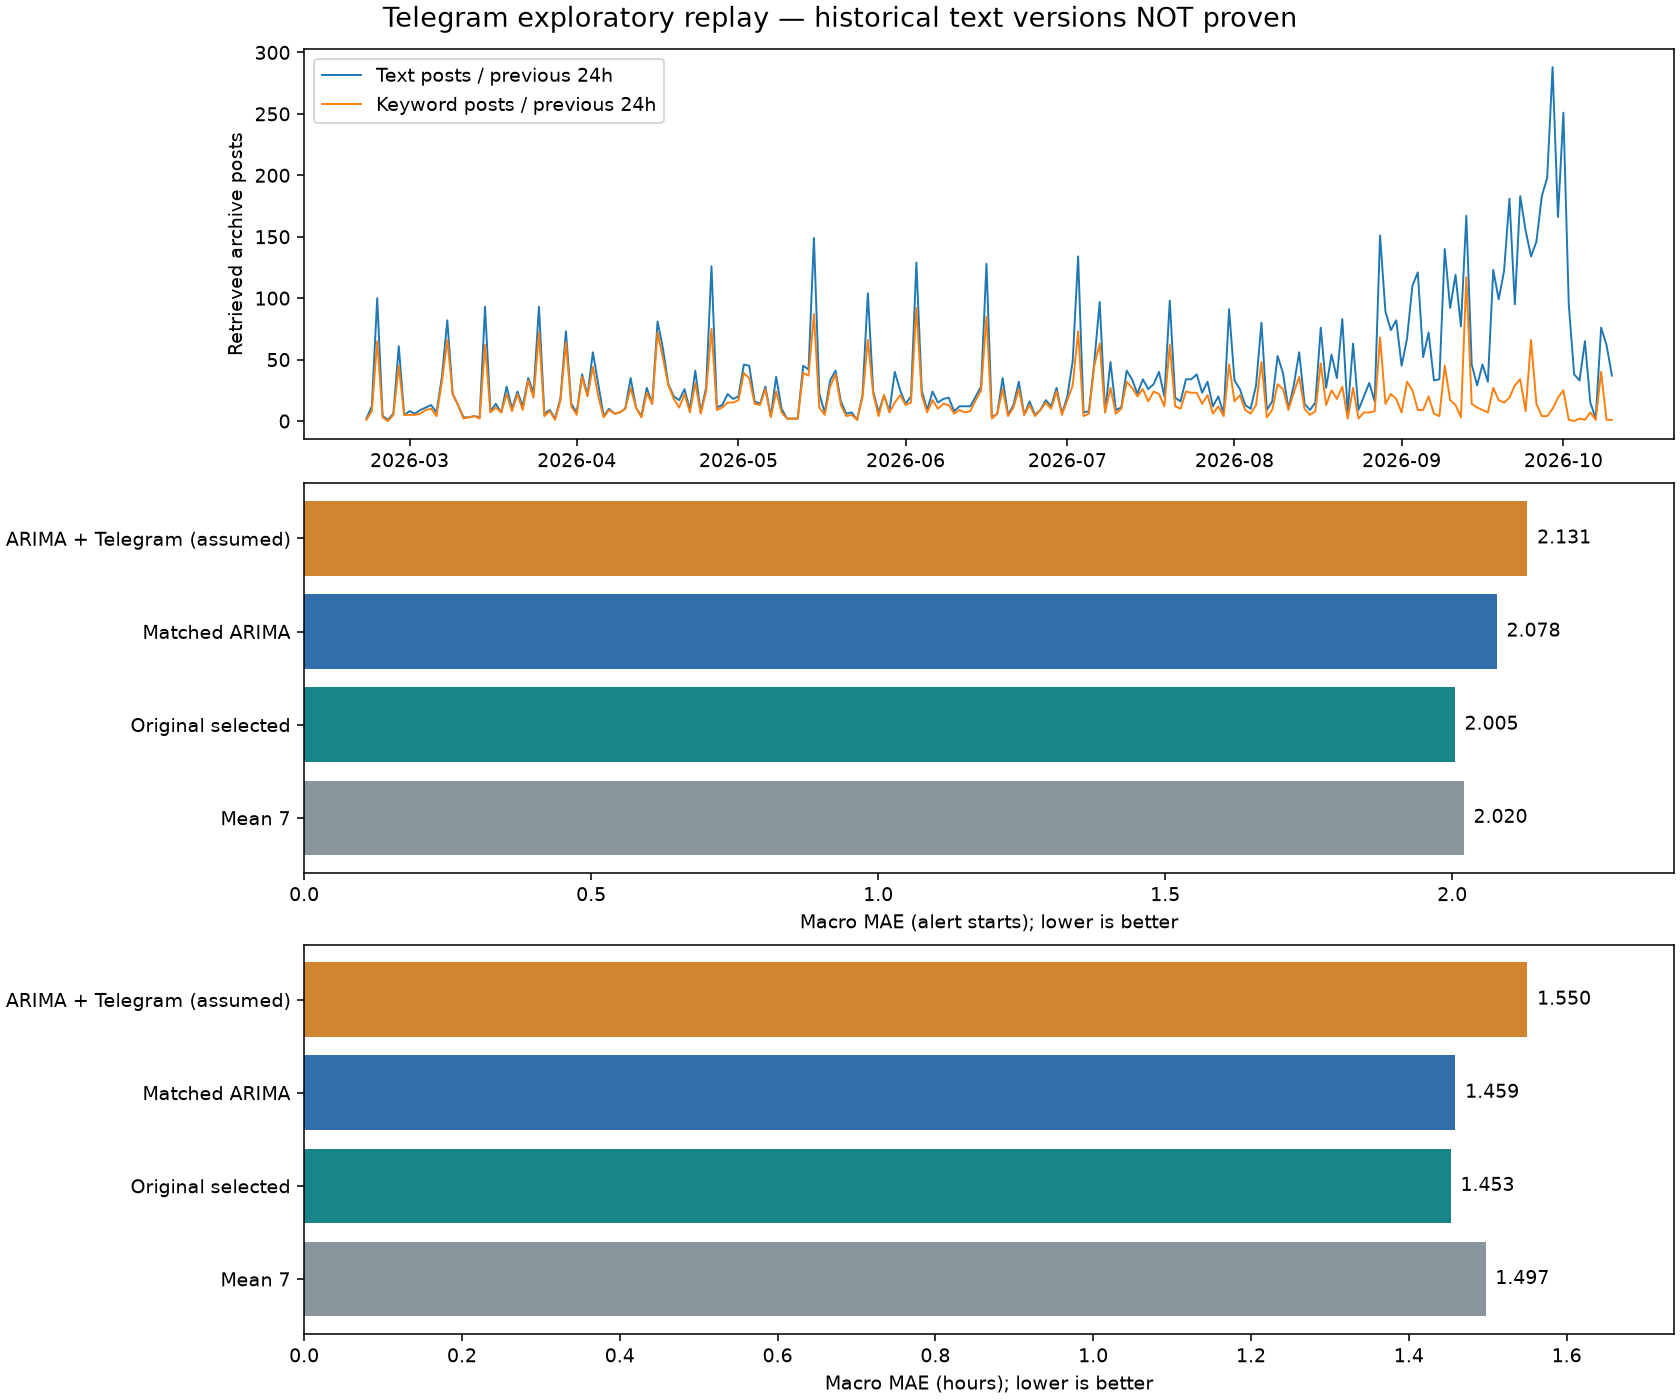

Підтвердженої користі Telegram не встановлено; потрібен новий перспективний протокол.


In [10]:
from airraid.telegram_experiment import independent_feature_audit, independent_metric_audit
TG = REPORTS/'telegram/publication_assumed'
display(json.loads((REPORTS/'telegram/observed/availability_audit.json').read_text()))
assert json.loads((REPORTS/'telegram/observed/status.json').read_text())['scores_produced'] is False
display(independent_feature_audit(DATA/'telegram/message_versions.csv.gz', TG/'daily_features.csv', TG))
display(independent_metric_audit(TG))
cross = json.loads((TG/'cross_platform_audit.json').read_text())
display(cross['summary'])
assert cross['promotion_blocked'] and not cross['summary']['offline_replay_passed']
display(pd.read_csv(TG/'comparison.csv'))
assert not pd.read_csv(TG/'comparison.csv').certified_success.any()
display(Image(filename=str(TG/'experiment.png')))
print('Підтвердженої користі Telegram не встановлено; потрібен новий перспективний протокол.')